# P30 Parts 1–3: Inventory control — DP, classic rules, Q-learning, and DQN

**Project question (P30):** when does reinforcement learning beat the classic ordering rules?

Part 1 builds everything the later parts compare against:

1. A Gymnasium environment for a shop with random demand, a delivery delay and lost sales.
2. The **exact optimum** from value iteration (Sutton & Barto, ch. 4) for short delays, L = 1, 2, 3.
3. The two industry rules, **base-stock** and **(s, S)**, with tuned parameters.
4. A fair evaluation following the course protocol.

Part 2 adds tabular Q-learning. Part 3 (sections 16–22) adds DQN for lead times L = 1 to 6. Both use this environment and the same evaluation code.

| Protocol rule | How Part 1 covers it |
|---|---|
| 1. Seeds | 10 evaluation seeds; 5 separate tuning seeds |
| 2. Equal budget | every method is scored on the same 10 x 20,000 days with the same demand (common random numbers) |
| 3. Learning curves | not applicable yet (no method learns); value-iteration convergence is shown instead |
| 4. Final performance | every policy is evaluated greedily on evaluation seeds never used for tuning |
| 5. Efficiency | wall-clock time for DP, tuning and evaluation, plus the hardware |
| 6. Sensitivity | cost against the base-stock level S, and gaps against the lost-sales penalty p |
| 7. Statistics (rliable IQM) | for the deep RL comparison in Part 3 |
| 8. Reproducibility | code in `src/inventory_rl`, pinned `requirements.txt`, tests in `tests/` |

**Part 2** (sections 9–15 below) adds tabular Q-learning with learning curves, greedy evaluation against the Part 1 baselines, α/ε sensitivity, and a dedicated compute-time table. Run all Part 1 cells before Part 2.

**Part 3** (sections 16–22) trains DQN at L = 1 to 6. Run Part 1 first. Part 2 does not have to be re-run; if `ql_summary` is already in memory, those rows are added to the comparison.


## 0. Setup

On Google Colab, set `REPO_URL` to your GitHub copy of this repository. The cell clones it and installs Gymnasium; the other libraries are already on Colab. Run locally, it only puts `src/` on the import path.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/YOUR-USERNAME/P30_inventory_rl.git"

if IN_COLAB:
    if not Path("/content/P30_inventory_rl").exists():
        !git clone -q {REPO_URL} /content/P30_inventory_rl
    %cd /content/P30_inventory_rl
    %pip install -q gymnasium==1.4.0

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
RESULTS = ROOT / "results" / "part1"
RESULTS.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: E:\MasterSem1\An2Sem1\P30_inventory_rl


In [2]:
import platform
import time
from dataclasses import asdict

import gymnasium as gym
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from gymnasium.utils.env_checker import check_env

from inventory_rl.config import DEFAULT, InventoryConfig
from inventory_rl.dp import value_iteration
from inventory_rl.env import InventoryEnv
from inventory_rl.evaluate import (BURN_IN, EVAL_DAYS, EVAL_SEEDS, TUNING_SEEDS,
                                   evaluate_policy, mean_ci, paired_gap_pct)
from inventory_rl.model import build_model, model_memory_mb
from inventory_rl.policies import BaseStockPolicy, SSPolicy, TabularPolicy, inventory_position
from inventory_rl.tuning import TUNING_DAYS, tune_base_stock, tune_ss
from inventory_rl import plotting

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110


def cpu_name():
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


hardware = {
    "cpu": cpu_name(),
    "logical cores": os.cpu_count(),
    "os": platform.platform(),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "gymnasium": gym.__version__,
    "colab": IN_COLAB,
}
pd.Series(hardware, name="value").to_frame()

,value
cpu,"AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD"
logical cores,16
os,Windows-11-10.0.26200-SP0
python,3.14.3
numpy,2.5.4
scipy,1.18.1
pandas,3.0.6
matplotlib,3.11.2
gymnasium,1.4.0
colab,False


## 1. The MDP

A shop sells one product. Every day it decides how much to order from its supplier. Demand is random, an order arrives **L days** after it is placed, unsold stock costs money to hold, and a customer who finds an empty shelf is lost.

**One day, in order**

1. The shop observes its state: the stock on its shelf and the orders still on their way.
2. It orders `a` units, paying `K` (a fixed cost, if `a > 0`) plus `c` per unit.
3. Demand `D ~ Poisson(lambda)` arrives. The shop sells `min(stock, D)`; the rest is lost and costs `p` per unit.
4. Leftover stock costs `h` per unit to hold overnight.
5. Next morning, the oldest order in transit is delivered. An order placed today can first be sold L days from now.

**States.** $S_t = (x_t,\, q_1, \dots, q_{L-1})$: stock on hand $x_t \in \{0,\dots,X_{max}\}$ and the orders in transit, where $q_1$ arrives tomorrow. For L = 1 the state is just $x_t$, because today's order arrives tomorrow morning.

**Actions.** $A_t \in \{0, 1, \dots, A_{max}\}$, the quantity ordered.

**Rewards.** $R_{t+1} = -\big(h\cdot\text{leftover} + p\cdot\text{lost sales} + K\cdot\mathbb{1}[A_t>0] + c\cdot A_t\big)$. Maximizing return is minimizing cost.

**Continuing task.** The shop never closes, so there is no terminal state. We train and solve with discount $\gamma = 0.99$. Methods are compared on the **long-run average cost per day**, measured over long simulations after a burn-in.

**Markov property.** Tomorrow's state depends only on today's state, today's order and today's demand. Demand is i.i.d., and every outstanding order is part of the state. With stock on hand alone (no pipeline), the state would *not* be Markov for L >= 2: two days with the same shelf can have different deliveries on the way.

**Modelling choices.**
- Shelf capacity $X_{max}$: stock above it on delivery is discarded. The overflow rate is reported below to show the cap almost never binds.
- For DP, demand is truncated where $P(D > D_{max}) < 10^{-8}$.
- The state space has $(X_{max}+1)(A_{max}+1)^{L-1}$ states. It grows exponentially with the delay, which is the scaling question of P30.

In [3]:
pd.Series(asdict(DEFAULT), name="default").to_frame().T

,L,lam,X_max,A_max,h,p,K,c,gamma
default,1.0,4.0,20.0,10.0,1.0,10.0,5.0,1.0,0.99


## 2. The environment

`InventoryEnv` is a standard Gymnasium environment (`reset`, `step`, observation and action spaces), so Q-learning in Part 2 and Stable-Baselines3 in Part 3 can use it unchanged. The DP model, the fast evaluation simulator and the environment all call the same one-day function, `dynamics.transition`, and the tests in `tests/` check that they agree.

Below, the environment passes Gymnasium's API checker. Then we trace one week with L = 2 under an (s, S) = (8, 14) rule and a fixed demand sequence, so every number can be checked by hand.

In [4]:
for L in (1, 2, 3):
    check_env(InventoryEnv(L=L), skip_render_check=True)
print("Gymnasium env_checker passed for L = 1, 2, 3")

cfg2 = DEFAULT.with_(L=2)
env = InventoryEnv(cfg2)
rule = SSPolicy(8, 14, cfg2)
week_demand = [3, 5, 2, 6, 4, 1, 7]
obs, _ = env.reset(options={"on_hand": 6, "pipeline": [0], "demands": week_demand})

rows = []
for day, _ in enumerate(week_demand, start=1):
    on_hand, in_transit = int(obs[0]), obs[1:].tolist()
    position = int(inventory_position(obs[:1], obs[None, 1:])[0])
    action = int(rule(obs[:1], obs[None, 1:])[0])
    obs, reward, terminated, truncated, info = env.step(action)
    rows.append(dict(day=day, on_hand=on_hand, in_transit=in_transit, position=position, order=action,
                     demand=info["demand"], sold=info["sold"], lost=info["lost"], holding=info["holding"],
                     lost_penalty=info["lost_penalty"], ordering=info["ordering"], cost=info["cost"]))
pd.DataFrame(rows).set_index("day")

Gymnasium env_checker passed for L = 1, 2, 3


,on_hand,in_transit,position,order,demand,sold,lost,holding,lost_penalty,ordering,cost
day,,,,,,,,,,,
1,6,[0],6,8,3,3,0,3.0,0.0,13.0,16.0
2,3,[8],11,0,5,3,2,0.0,20.0,0.0,20.0
3,8,[0],8,6,2,2,0,6.0,0.0,11.0,17.0
4,6,[6],12,0,6,6,0,0.0,0.0,0.0,0.0
5,6,[0],6,8,4,4,0,2.0,0.0,13.0,15.0
6,2,[8],10,0,1,1,0,1.0,0.0,0.0,1.0
7,9,[0],9,0,7,7,0,2.0,0.0,0.0,2.0


On day 1 the position is 6 <= s = 8, so the shop orders up to 14 (8 units). That order shows up in transit on day 2 and on the shelf on day 3. The lost-sales penalty dominates whenever the shelf runs empty.

### How fast the state space grows

Before solving anything: the size of the exact DP model as the delivery delay grows. The model stores the next state and the cost for every (state, action, demand) triple.

In [5]:
growth = pd.DataFrame([
    {"L": L, "states": DEFAULT.with_(L=L).n_states,
     "state-action pairs": DEFAULT.with_(L=L).n_states * DEFAULT.n_actions,
     "DP model memory (MB)": model_memory_mb(DEFAULT.with_(L=L))}
    for L in range(1, 7)
]).set_index("L")
growth.to_csv(RESULTS / "state_space_growth.csv")
growth.style.format({"states": "{:,}", "state-action pairs": "{:,}", "DP model memory (MB)": "{:,.1f}"})

,states,state-action pairs,DP model memory (MB)
L,,,
1,21,231,0.1
2,231,"2,541",0.6
3,"2,541","27,951",7.0
4,"27,951","307,461",77.5
5,"307,461","3,382,071",852.3
6,"3,382,071","37,202,781","9,375.1"


Every extra day of delay multiplies the state space by 11. L = 1 to 3 solve in seconds. L = 4 still fits (about 80 MB, tens of seconds). L = 5 needs about 0.85 GB and L = 6 about 9 GB, which is where exact DP stops being practical and Part 3's approximate methods come in.

## 3. Value iteration: the exact optimum for short delays

Synchronous value iteration from $V_0 = 0$:

$$V_{k+1}(s) = \max_a \sum_{d} P(D=d)\,\big[r(s,a,d) + \gamma V_k(s'(s,a,d))\big]$$

It stops when $\max_s |V_{k+1}(s) - V_k(s)| < \varepsilon(1-\gamma)/2\gamma$ with $\varepsilon = 0.01$, which guarantees the greedy policy is within 0.01 of optimal in discounted value.

In [6]:
LEAD_TIMES = (1, 2, 3)
configs = {L: DEFAULT.with_(L=L) for L in LEAD_TIMES}
models, vi_results = {}, {}
rows = []
for L, cfg in configs.items():
    models[L] = build_model(cfg)
    vi_results[L] = value_iteration(models[L])
    rows.append({"L": L, "states": cfg.n_states, "build model (s)": models[L].build_seconds,
                 "value iteration (s)": vi_results[L].seconds, "sweeps": vi_results[L].sweeps,
                 "final residual": vi_results[L].residuals[-1]})
dp_table = pd.DataFrame(rows).set_index("L")
dp_table.to_csv(RESULTS / "dp_timing.csv")
dp_table

,states,build model (s),value iteration (s),sweeps,final residual
L,,,,,
1,21,0.032,0.014,1240,5.017e-05
2,231,0.001,0.093,1245,5.009e-05
3,2541,0.013,1.615,1248,5.013e-05


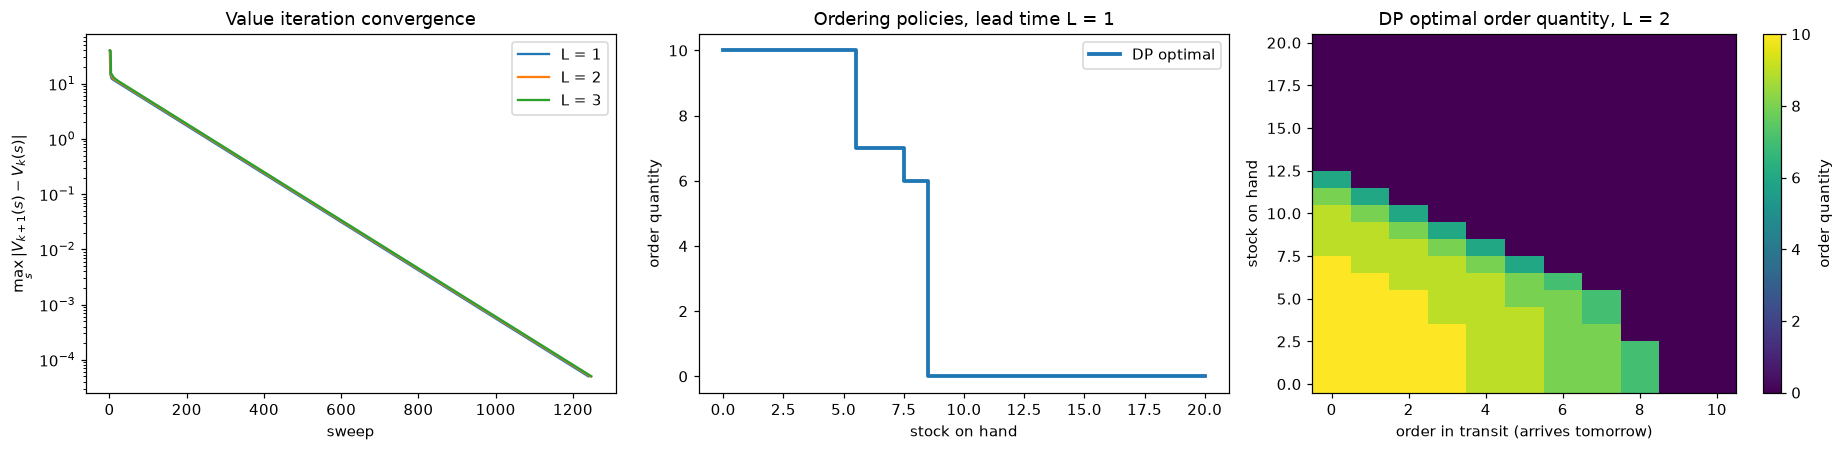

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
plotting.plot_residuals(vi_results, ax=axes[0])
plotting.plot_policy_L1(vi_results[1].policy, configs[1], ax=axes[1])
plotting.plot_policy_L2(vi_results[2].policy, configs[2], ax=axes[2])
fig.tight_layout()
plotting.save(fig, RESULTS / "dp_convergence_and_policies.png")
plt.show()

**Reading the plots.**
- **Convergence** is geometric at rate $\gamma = 0.99$, so about 1,250 sweeps are needed regardless of L. The cost per sweep grows with the number of states.
- **L = 1:** the optimal policy orders nothing when the shelf holds 9 or more units. Otherwise it orders up to about 14, limited by the maximum order of 10 when the shelf is nearly empty. That is almost exactly an (s, S) rule.
- **L = 2:** the boundary between ordering and not ordering runs diagonally. One unit on the shelf is roughly worth one unit in transit, which is why the classic rules look at the **inventory position** (on hand + in transit) instead of the shelf alone.

## 4. Classic ordering rules, tuned

Both rules look at the inventory position $y = x + \sum_i q_i$:

- **Base-stock(S):** every day, order $\min(S - y, A_{max})$ if $y < S$.
- **(s, S):** only when $y \le s$, order $\min(S - y, A_{max})$; otherwise order nothing. Fewer, larger orders save the fixed cost K.

Tuning is a full grid search: every S, and every pair s < S, up to the largest reachable position. Each candidate is scored by its average cost over 5 **tuning seeds** of 10,000 days, after a 1,000-day burn-in. The evaluation seeds are never used for tuning.

In [8]:
bs_tuning, ss_tuning = {}, {}
rows = []
for L, cfg in configs.items():
    bs_tuning[L] = tune_base_stock(cfg)
    ss_tuning[L] = tune_ss(cfg)
    rows.append({"L": L,
                 "base-stock S": bs_tuning[L].best["S"], "base-stock tuning cost": bs_tuning[L].best["cost"],
                 "(s,S) s": ss_tuning[L].best["s"], "(s,S) S": ss_tuning[L].best["S"],
                 "(s,S) tuning cost": ss_tuning[L].best["cost"],
                 "(s,S) pairs searched": len(ss_tuning[L].table),
                 "tuning time (s)": bs_tuning[L].seconds + ss_tuning[L].seconds})
tuning_table = pd.DataFrame(rows).set_index("L")
tuning_table.to_csv(RESULTS / "tuned_rules.csv")
pd.concat({L: t.table for L, t in ss_tuning.items()}, names=["L"]).to_csv(RESULTS / "ss_tuning_grid.csv")
pd.concat({L: t.table for L, t in bs_tuning.items()}, names=["L"]).to_csv(RESULTS / "base_stock_tuning_grid.csv")
tuning_table

,base-stock S,base-stock tuning cost,"(s,S) s","(s,S) S","(s,S) tuning cost","(s,S) pairs searched",tuning time (s)
L,,,,,,,
1,11,13.890,8,14,12.784,231,2.117
2,15,14.571,12,19,13.533,496,2.320
3,19,15.044,16,22,13.930,861,2.837


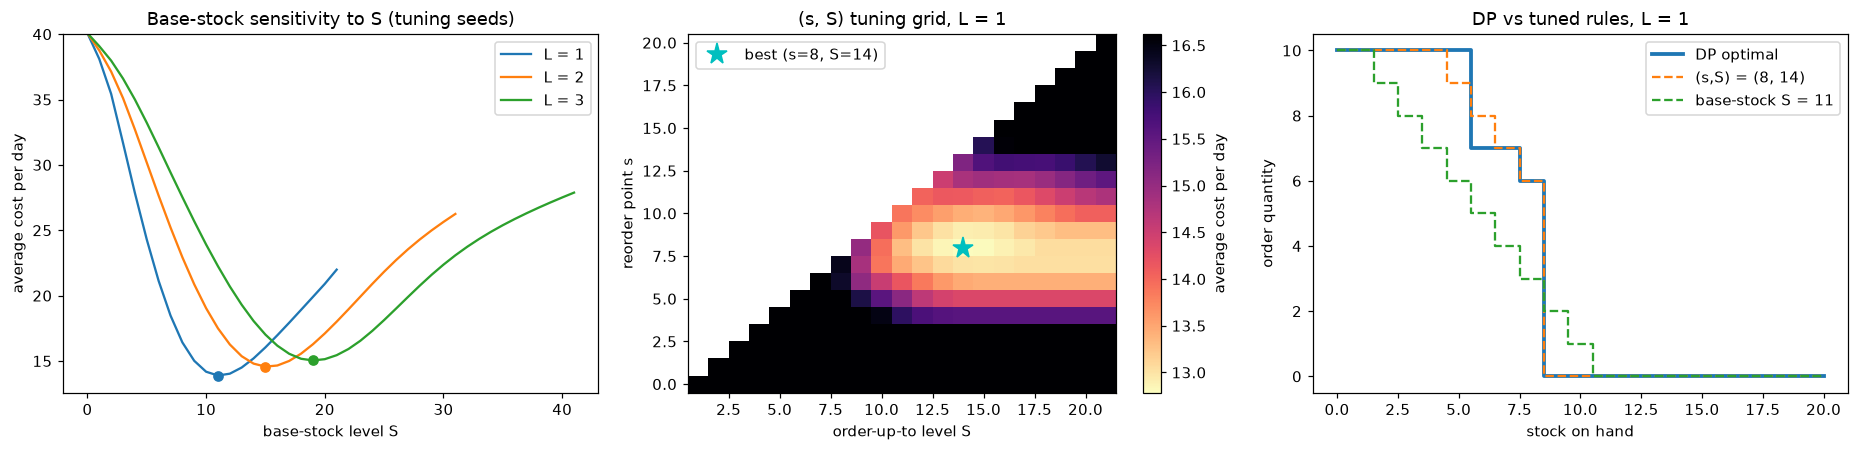

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
plotting.plot_cost_vs_S({L: t.table for L, t in bs_tuning.items()}, ax=axes[0])
axes[0].set_ylim(top=40)
plotting.plot_ss_heatmap(ss_tuning[1].table, ax=axes[1])
axes[1].set_title("(s, S) tuning grid, L = 1")
cfg1 = configs[1]
plotting.plot_policy_L1(vi_results[1].policy, cfg1, ax=axes[2], rules={
    f"(s,S) = ({ss_tuning[1].best['s']}, {ss_tuning[1].best['S']})":
        SSPolicy(ss_tuning[1].best["s"], ss_tuning[1].best["S"], cfg1),
    f"base-stock S = {bs_tuning[1].best['S']}": BaseStockPolicy(bs_tuning[1].best["S"], cfg1),
})
axes[2].set_title("DP vs tuned rules, L = 1")
fig.tight_layout()
plotting.save(fig, RESULTS / "rule_tuning.png")
plt.show()

**Sensitivity to S (protocol rule 6).** The base-stock cost curve is asymmetric:
- Setting S too low is expensive, because the shelf empties and every lost sale costs p = 10.
- Setting S too high costs only the holding cost h = 1 per unit, so the curve rises slowly.
- The best S grows with the delay, because the stock must cover demand over L + 1 days.

The (s, S) heatmap has a broad low-cost valley, so the rule is fairly robust to its parameters. On the right, the tuned (s, S) rule almost reproduces the DP policy at L = 1, while base-stock orders small amounts every day and keeps paying K.

## 5. Final evaluation

Each policy is evaluated greedily (no exploration, no tuning) on the **10 evaluation seeds**. Each seed is 20,000 days after a 1,000-day burn-in, and every method sees exactly the same demand sequence for a given seed. Gaps are computed per seed and then averaged (a paired comparison), so the confidence intervals reflect differences between methods rather than the luck of the demand draw.

Methods compared:
- **DP optimal:** greedy policy from value iteration (needs the full model).
- **(s,S) tuned** and **base-stock tuned:** the industry rules with grid-searched parameters.
- **base-stock naive:** S = mean demand over the L + 1 days an order must cover, i.e. what an untuned rule of thumb would do. It shows how much the tuning itself is worth.

The **best rule** at each L is whichever tuned rule had the lower *tuning* cost, so it is chosen without looking at the evaluation seeds.

In [10]:
def policies_for(L):
    cfg = configs[L]
    bs, ss = bs_tuning[L].best, ss_tuning[L].best
    naive_S = int(np.ceil(cfg.lam * (L + 1)))
    return {
        "DP optimal": (TabularPolicy(vi_results[L].policy, cfg), "-", vi_results[L].seconds + models[L].build_seconds),
        "(s,S) tuned": (SSPolicy(ss["s"], ss["S"], cfg), f"s={ss['s']}, S={ss['S']}", ss_tuning[L].seconds),
        "base-stock tuned": (BaseStockPolicy(bs["S"], cfg), f"S={bs['S']}", bs_tuning[L].seconds),
        "base-stock naive": (BaseStockPolicy(naive_S, cfg), f"S={naive_S}", 0.0),
    }


def evaluate_all(policies, cfg, best_rule):
    sims = {name: evaluate_policy(pol, cfg) for name, (pol, _, _) in policies.items()}
    rows = []
    for name, (pol, params, prep_seconds) in policies.items():
        r = sims[name]
        cost, cost_ci = mean_ci(r.avg_cost)
        gap_dp, gap_dp_ci = paired_gap_pct(r.avg_cost, sims["DP optimal"].avg_cost)
        gap_rule, gap_rule_ci = paired_gap_pct(r.avg_cost, sims[best_rule].avg_cost)
        rows.append(dict(method=name, params=params, cost=cost, cost_ci=cost_ci,
                         gap_dp_pct=gap_dp, gap_dp_ci=gap_dp_ci,
                         gap_best_rule_pct=gap_rule, gap_best_rule_ci=gap_rule_ci,
                         fill_rate=r.fill_rate.mean(), order_freq=r.order_freq.mean(),
                         holding=r.avg_holding.mean(), lost_penalty=r.avg_lost_penalty.mean(),
                         ordering=r.avg_ordering.mean(), overflow_per_day=r.overflow_rate.mean(),
                         prep_seconds=prep_seconds, eval_seconds=r.seconds))
    per_seed = pd.DataFrame({name: r.avg_cost for name, r in sims.items()}, index=pd.Index(EVAL_SEEDS, name="seed"))
    return pd.DataFrame(rows), per_seed


summaries, per_seed_costs = [], {}
for L, cfg in configs.items():
    best_rule = "(s,S) tuned" if ss_tuning[L].best["cost"] <= bs_tuning[L].best["cost"] else "base-stock tuned"
    table, per_seed = evaluate_all(policies_for(L), cfg, best_rule)
    table.insert(0, "L", L)
    table["best_rule"] = best_rule
    summaries.append(table)
    per_seed_costs[L] = per_seed

summary = pd.concat(summaries, ignore_index=True)
summary.to_csv(RESULTS / "final_evaluation.csv", index=False)
pd.concat(per_seed_costs, names=["L"]).to_csv(RESULTS / "per_seed_costs.csv")

display_cols = ["L", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci",
                "gap_best_rule_pct", "gap_best_rule_ci", "fill_rate", "order_freq", "overflow_per_day"]
summary[display_cols].set_index(["L", "method"])

params    cost  cost_ci  gap_dp_pct  gap_dp_ci  \
L method                                                                 
1 DP optimal                 -  12.765    0.034       0.000      0.000   
  (s,S) tuned        s=8, S=14  12.781    0.030       0.125      0.143   
  base-stock tuned        S=11  13.876    0.032       8.706      0.205   
  base-stock naive         S=8  16.386    0.053      28.369      0.284   
2 DP optimal                 -  13.349    0.041       0.000      0.000   
  (s,S) tuned       s=12, S=19  13.524    0.050       1.307      0.139   
  base-stock tuned        S=15  14.576    0.042       9.195      0.146   
  base-stock naive        S=12  16.193    0.056      21.304      0.177   
3 DP optimal                 -  13.700    0.045       0.000      0.000   
  (s,S) tuned       s=16, S=22  13.957    0.048       1.874      0.147   
  base-stock tuned        S=19  15.064    0.041       9.958      0.180   
  base-stock naive        S=16  16.124    0.062      17.694      0.146   

                    gap_best_rule_pct  gap_best_rule_ci  fill_rate  \
L method                                                             
1 DP optimal                   -0.124             0.143      0.950   
  (s,S) tuned                   0.000             0.000      0.948   
  base-stock tuned              8.570             0.148      0.955   
  base-stock naive             28.209             0.256      0.830   
2 DP optimal                   -1.290             0.136      0.937   
  (s,S) tuned                   0.000             0.000      0.947   
  base-stock tuned              7.786             0.164      0.944   
  base-stock naive             19.740             0.119      0.848   
3 DP optimal                   -1.839             0.142      0.928   
  (s,S) tuned                   0.000             0.000      0.935   
  base-stock tuned              7.936             0.183      0.939   
  base-stock naive             15.530             0.142      0.861   

                    order_freq  overflow_per_day  
L method                                          
1 DP optimal             0.490         0.000e+00  
  (s,S) tuned            0.483         0.000e+00  
  base-stock tuned       0.982         0.000e+00  
  base-stock naive       0.981         0.000e+00  
2 DP optimal             0.450         0.000e+00  
  (s,S) tuned            0.443         0.000e+00  
  base-stock tuned       0.982         0.000e+00  
  base-stock naive       0.980         0.000e+00  
3 DP optimal             0.452         9.000e-05  
  (s,S) tuned            0.482         4.500e-05  
  base-stock tuned       0.981         0.000e+00  
  base-stock naive       0.979         0.000e+00

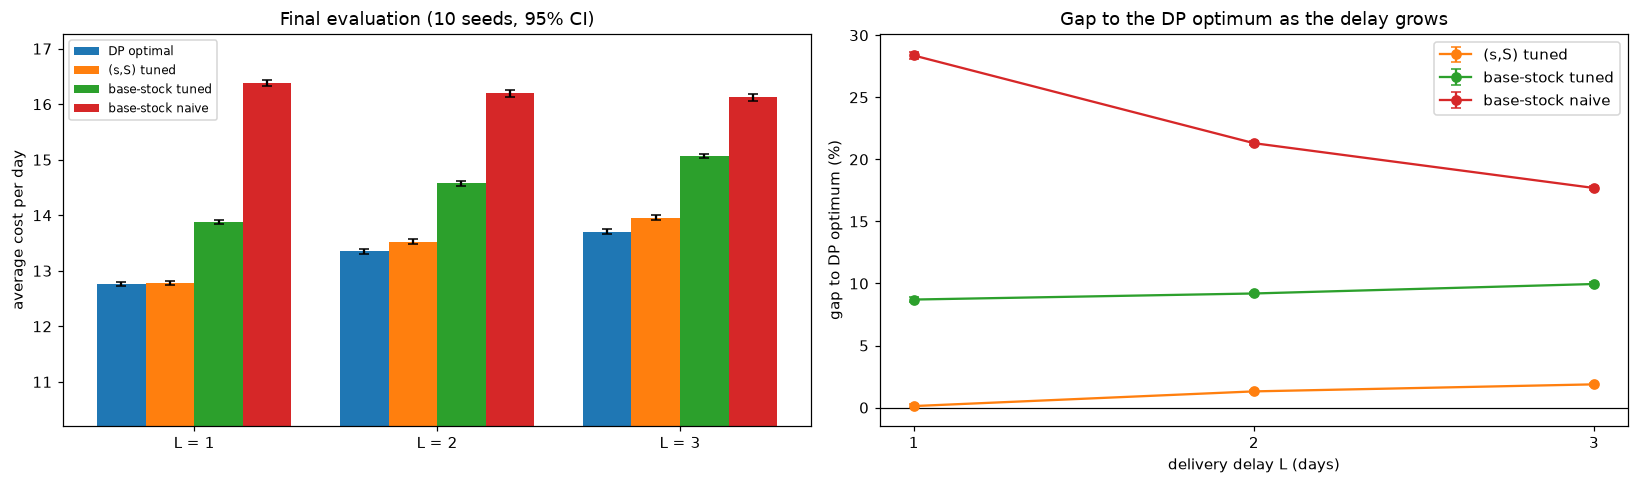

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
plotting.plot_methods_by_L(summary, ax=axes[0])
plotting.plot_sensitivity(summary, x="L", ax=axes[1])
axes[1].set_xticks(list(LEAD_TIMES))
axes[1].set_xlabel("delivery delay L (days)")
axes[1].set_title("Gap to the DP optimum as the delay grows")
fig.tight_layout()
plotting.save(fig, RESULTS / "final_evaluation.png")
plt.show()

In [12]:
breakdown = summary.set_index(["L", "method"])[["holding", "lost_penalty", "ordering", "cost"]]
breakdown.columns = ["holding", "lost-sales penalty", "ordering", "total"]
breakdown

holding  lost-sales penalty  ordering   total
L method                                                         
1 DP optimal          4.527               1.986     6.252  12.765
  (s,S) tuned         4.501               2.071     6.210  12.781
  base-stock tuned    3.357               1.788     8.732  13.876
  base-stock naive    1.359               6.802     8.225  16.386
2 DP optimal          4.837               2.514     5.997  13.349
  (s,S) tuned         5.395               2.128     6.001  13.524
  base-stock tuned    3.666               2.224     8.686  14.576
  base-stock naive    1.822               6.078     8.293  16.193
3 DP optimal          4.859               2.868     5.973  13.700
  (s,S) tuned         5.201               2.606     6.150  13.957
  base-stock tuned    3.970               2.430     8.665  15.064
  base-stock naive    2.222               5.560     8.341  16.124

## 6. Sensitivity to the lost-sales penalty p

How much the policies leave on the table depends on the cost structure. Here the penalty per lost sale is varied (p = 5, 10, 20) for L = 1 and L = 2. For each p, everything is re-solved and re-tuned from scratch, then evaluated with the same protocol.

In [13]:
sens_rows = []
t0 = time.perf_counter()
for L in (1, 2):
    for p in (5.0, 10.0, 20.0):
        cfg = DEFAULT.with_(L=L, p=p)
        vi = value_iteration(build_model(cfg))
        bs, ss = tune_base_stock(cfg), tune_ss(cfg)
        best_rule = "(s,S) tuned" if ss.best["cost"] <= bs.best["cost"] else "base-stock tuned"
        pols = {
            "DP optimal": (TabularPolicy(vi.policy, cfg), "-", vi.seconds),
            "(s,S) tuned": (SSPolicy(ss.best["s"], ss.best["S"], cfg), f"s={ss.best['s']}, S={ss.best['S']}", ss.seconds),
            "base-stock tuned": (BaseStockPolicy(bs.best["S"], cfg), f"S={bs.best['S']}", bs.seconds),
        }
        table, _ = evaluate_all(pols, cfg, best_rule)
        table.insert(0, "p", p)
        table.insert(0, "L", L)
        sens_rows.append(table)
sensitivity = pd.concat(sens_rows, ignore_index=True)
sensitivity.to_csv(RESULTS / "sensitivity_p.csv", index=False)
print(f"sensitivity study: {time.perf_counter() - t0:.1f} s")
sensitivity[["L", "p", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci", "fill_rate"]].set_index(["L", "p", "method"])

sensitivity study: 20.2 s


params    cost  cost_ci  gap_dp_pct  gap_dp_ci  \
L p    method                                                                 
1 5.0  DP optimal                 -  11.303    0.020       0.000      0.000   
       (s,S) tuned        s=6, S=13  11.344    0.027       0.363      0.170   
       base-stock tuned        S=10  12.681    0.021      12.193      0.128   
  10.0 DP optimal                 -  12.765    0.034       0.000      0.000   
       (s,S) tuned        s=8, S=14  12.781    0.030       0.125      0.143   
       base-stock tuned        S=11  13.876    0.032       8.706      0.205   
  20.0 DP optimal                 -  14.016    0.034       0.000      0.000   
       (s,S) tuned       s=10, S=15  14.040    0.036       0.172      0.087   
       base-stock tuned        S=13  15.065    0.039       7.487      0.208   
2 5.0  DP optimal                 -  11.575    0.024       0.000      0.000   
       (s,S) tuned       s=10, S=16  11.894    0.023       2.756      0.128   
       base-stock tuned        S=13  13.056    0.027      12.790      0.134   
  10.0 DP optimal                 -  13.349    0.041       0.000      0.000   
       (s,S) tuned       s=12, S=19  13.524    0.050       1.307      0.139   
       base-stock tuned        S=15  14.576    0.042       9.195      0.146   
  20.0 DP optimal                 -  14.892    0.045       0.000      0.000   
       (s,S) tuned       s=14, S=21  14.981    0.056       0.602      0.242   
       base-stock tuned        S=17  15.949    0.049       7.103      0.161   

                         fill_rate  
L p    method                       
1 5.0  DP optimal            0.878  
       (s,S) tuned           0.887  
       base-stock tuned      0.926  
  10.0 DP optimal            0.950  
       (s,S) tuned           0.948  
       base-stock tuned      0.955  
  20.0 DP optimal            0.983  
       (s,S) tuned           0.984  
       base-stock tuned      0.986  
2 5.0  DP optimal            0.870  
       (s,S) tuned           0.886  
       base-stock tuned      0.887  
  10.0 DP optimal            0.937  
       (s,S) tuned           0.947  
       base-stock tuned      0.944  
  20.0 DP optimal            0.973  
       (s,S) tuned           0.977  
       base-stock tuned      0.977

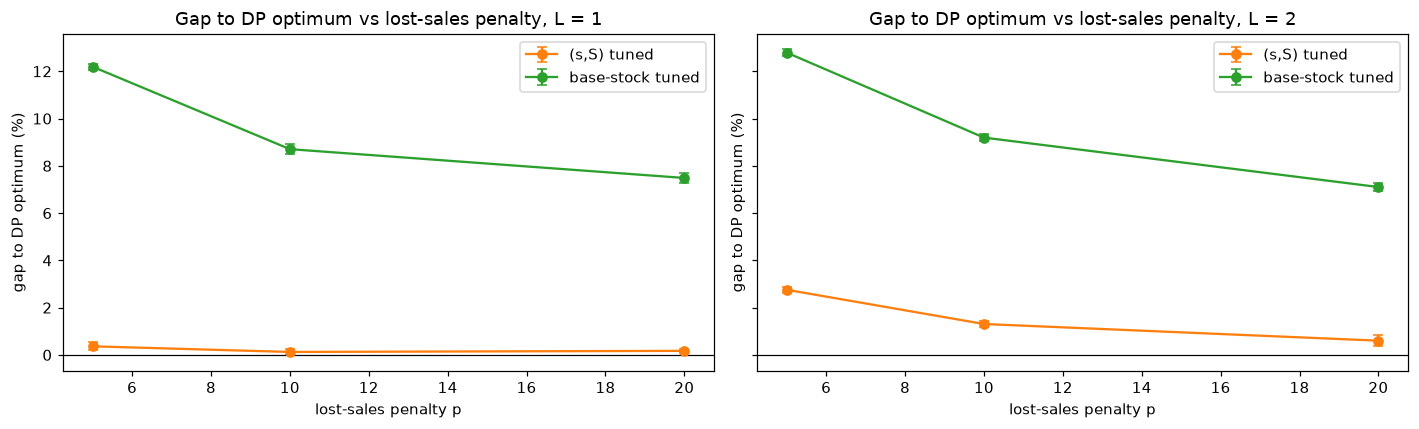

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, L in zip(axes, (1, 2)):
    plotting.plot_sensitivity(sensitivity[sensitivity.L == L], x="p", ax=ax)
    ax.set_title(f"Gap to DP optimum vs lost-sales penalty, L = {L}")
    ax.set_xlabel("lost-sales penalty p")
fig.tight_layout()
plotting.save(fig, RESULTS / "sensitivity_p.png")
plt.show()

**Reading the sensitivity results.**
- **Base-stock** suffers most when lost sales are cheap (p = 5). Shortages then matter less than the fixed cost of ordering every day, and that cost is exactly what base-stock ignores.
- **(s, S) at L = 1** stays within about 0.4% of optimal for every p.
- **(s, S) at L = 2** loses more when p is small (about 2.8% at p = 5, 0.6% at p = 20). When stockouts are cheap, the optimal policy deliberately runs the shelf low and times orders using the pipeline in detail, which a single position threshold cannot express.

So how much there is to gain over the industry rules depends on both the delay and the cost structure. Parts 2 and 3 will test whether learned policies capture that gain.

## 7. Compute cost (protocol rule 5)

Wall-clock seconds on the hardware listed in the setup cell:
- **preparation:** building the model and running value iteration for DP, or the full grid search for the rules
- **evaluation:** simulating 10 seeds x 21,000 days, vectorized over seeds

In [15]:
timing = summary.pivot(index="method", columns="L", values="prep_seconds").round(2)
timing.columns = [f"prep L={L} (s)" for L in timing.columns]
eval_time = summary.pivot(index="method", columns="L", values="eval_seconds").round(2)
eval_time.columns = [f"eval L={L} (s)" for L in eval_time.columns]
compute = pd.concat([timing, eval_time], axis=1)
compute.to_csv(RESULTS / "compute_time.csv")
print(hardware["cpu"], "|", hardware["logical cores"], "logical cores |", hardware["os"])
compute

AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD | 16 logical cores | Windows-11-10.0.26200-SP0


,prep L=1 (s),prep L=2 (s),prep L=3 (s),eval L=1 (s),eval L=2 (s),eval L=3 (s)
method,,,,,,
"(s,S) tuned",1.11,1.29,1.74,0.38,0.41,0.42
DP optimal,0.05,0.09,1.63,0.28,0.32,0.31
base-stock naive,0.00,0.00,0.00,0.38,0.40,0.40
base-stock tuned,1.00,1.03,1.09,0.38,0.39,0.40


## 8. Summary for Presentation 1

In [16]:
key = summary[summary.method != "DP optimal"].set_index(["L", "method"])[["cost", "gap_dp_pct", "gap_dp_ci"]]
for L in LEAD_TIMES:
    dp_cost = summary.query("L == @L and method == 'DP optimal'").cost.item()
    ss = key.loc[(L, "(s,S) tuned")]
    bs = key.loc[(L, "base-stock tuned")]
    nv = key.loc[(L, "base-stock naive")]
    print(f"L={L}: DP {dp_cost:.2f}/day | (s,S) +{ss.gap_dp_pct:.2f}% (+/-{ss.gap_dp_ci:.2f}) | "
          f"base-stock +{bs.gap_dp_pct:.1f}% | naive base-stock +{nv.gap_dp_pct:.1f}%")

L=1: DP 12.77/day | (s,S) +0.12% (+/-0.14) | base-stock +8.7% | naive base-stock +28.4%
L=2: DP 13.35/day | (s,S) +1.31% (+/-0.14) | base-stock +9.2% | naive base-stock +21.3%
L=3: DP 13.70/day | (s,S) +1.87% (+/-0.15) | base-stock +10.0% | naive base-stock +17.7%


**Findings so far** (numbers are in the table above and in `results/part1/`):

1. **The MDP is solved exactly for L = 1 to 3** in at most a couple of seconds. This gives a ground-truth optimum against which every later method is measured.
2. **The tuned (s, S) rule is almost optimal at L = 1.** Its gap is within the confidence interval of zero, and the DP policy itself has an (s, S) shape. With a short delay there is little for RL to gain.
3. **The (s, S) gap grows with the delay**, from about 0.1% at L = 1 to about 2% at L = 3. Under lost sales the inventory position stops being a sufficient summary once more orders are in transit, so the optimal policy depends on *which* orders arrive *when*. This is where a learned policy could pay off.
4. **Base-stock is about 9 to 10% worse than optimal** with a fixed order cost K = 5, because it orders every day. Tuning still matters: the naive rule of thumb is 18 to 28% worse than optimal.
5. **Cost structure matters too.** At L = 2 the (s, S) gap ranges from 0.6% (p = 20) to 2.8% (p = 5).
6. **Exact DP stops scaling at L = 5 to 6** (model memory 0.85 GB to 9 GB). That leaves room for approximate methods.

**Next (Part 2):** tabular Q-learning on the same environment for L = 1 to 3. It will be evaluated with learning curves over 10 seeds, sample efficiency (environment steps to come within 5% of the DP optimum) and sensitivity to alpha and epsilon. The question is how close model-free learning gets to the optimum computed here.

## 9. Part 2 setup: tabular Q-learning

Part 1 gave an exact DP optimum and tuned industry rules for L = 1, 2, 3. Part 2 asks how close **model-free** tabular Q-learning gets to that optimum under the course protocol.

| Protocol piece | Part 2 choice |
|---|---|
| Seeds | 10 training seeds; final greedy eval on the same 10 `EVAL_SEEDS` as Part 1 |
| Equal budget | 200,000 environment steps per seed for every L and every sensitivity run |
| Learning curves | Greedy checkpoint cost every 10,000 steps (mean ± 95% CI) |
| Final performance | Greedy policy (no exploration), evaluated like Part 1 |
| Efficiency | Wall-clock train/eval time + steps to within 5% of DP cost |
| Sensitivity | Learning rate α and exploration ε |

Requires Part 1 cells above (`vi_results`, `ss_tuning`, `bs_tuning`, `summary`, `configs`).

In [17]:
from inventory_rl.agents import train_q_learning
from inventory_rl.evaluate import EVAL_SEEDS, evaluate_policy, mean_ci, paired_gap_pct
from inventory_rl.policies import TabularPolicy

PART2 = ROOT / "results" / "part2"
PART2.mkdir(parents=True, exist_ok=True)

TRAIN_STEPS = 200_000
EVAL_EVERY = 10_000
TRAIN_SEEDS = tuple(range(10))
ALPHA = 0.1
EPSILON = 0.1
CHECKPOINT_DAYS = 2_000
CHECKPOINT_BURN_IN = 200

# DP reference costs from Part 1 final evaluation (average over eval seeds)
dp_costs = {
    int(L): float(summary.query("L == @L and method == 'DP optimal'").cost.item())
    for L in LEAD_TIMES
}
ss_costs = {
    int(L): float(summary.query("L == @L and method == '(s,S) tuned'").cost.item())
    for L in LEAD_TIMES
}
print("DP costs:", dp_costs)
print("Part 2 budget: ", TRAIN_STEPS, "steps ×", len(TRAIN_SEEDS), "seeds × L in", LEAD_TIMES)

DP costs: {1: 12.76503, 2: 13.349065, 3: 13.699985000000002}
Part 2 budget:  200000 steps × 10 seeds × L in (1, 2, 3)


## 10. Train Q-learning

For each lead time and seed we run one **continuing** trajectory (no artificial episode ends). At each checkpoint we freeze a greedy policy and estimate average daily cost on a short roll-out. Sample efficiency is the first checkpoint within **5%** of the Part 1 DP evaluation cost.

In [18]:
ql_runs = {L: [] for L in LEAD_TIMES}  # list of TrainResult per L
t_train = time.perf_counter()
for L in LEAD_TIMES:
    cfg = configs[L]
    for seed in TRAIN_SEEDS:
        ql_runs[L].append(
            train_q_learning(
                cfg,
                seed=seed,
                total_steps=TRAIN_STEPS,
                alpha=ALPHA,
                epsilon=EPSILON,
                eval_every=EVAL_EVERY,
                checkpoint_days=CHECKPOINT_DAYS,
                checkpoint_burn_in=CHECKPOINT_BURN_IN,
                target_cost=dp_costs[L],
            )
        )
    print(f"L={L}: mean train time {np.mean([r.seconds for r in ql_runs[L]]):.1f}s, "
          f"final checkpoint cost {np.mean([r.eval_costs[-1] for r in ql_runs[L]]):.2f}")
print(f"total training wall time: {time.perf_counter() - t_train:.1f}s")

# Persist curves
steps0 = ql_runs[LEAD_TIMES[0]][0].checkpoints
np.savez(
    PART2 / "learning_curves.npz",
    steps=steps0,
    **{f"L{L}": np.stack([r.eval_costs for r in ql_runs[L]]) for L in LEAD_TIMES},
    **{f"steps_to_target_L{L}": np.array([r.steps_to_target for r in ql_runs[L]]) for L in LEAD_TIMES},
    **{f"train_seconds_L{L}": np.array([r.seconds for r in ql_runs[L]]) for L in LEAD_TIMES},
)

L=1: mean train time 3.6s, final checkpoint cost 18.27


L=2: mean train time 4.6s, final checkpoint cost 23.65


L=3: mean train time 5.0s, final checkpoint cost 25.12
total training wall time: 131.1s


## 11. Learning curves

Mean greedy checkpoint cost across the 10 training seeds, with a 95% confidence band. Dotted horizontal lines are the Part 1 DP costs; dashed lines are tuned (s, S).

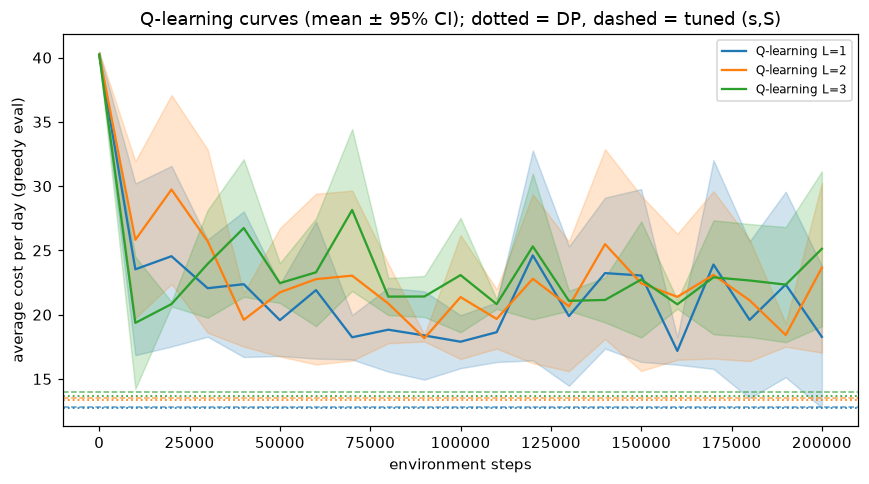

In [19]:
curves = {
    L: (ql_runs[L][0].checkpoints, np.stack([r.eval_costs for r in ql_runs[L]]))
    for L in LEAD_TIMES
}
fig, ax = plt.subplots(figsize=(8, 4.5))
plotting.plot_learning_curves(curves, dp_costs, ss_costs, ax=ax)
fig.tight_layout()
plotting.save(fig, PART2 / "learning_curves.png")
plt.show()

## 12. Final evaluation of greedy Q-learning

For each L we average the Q-tables across training seeds, take the greedy policy, and evaluate it with the **same** `EVAL_SEEDS` and common-random-numbers protocol as Part 1. Gaps to DP and to the best tuned rule are paired across those seeds.

In [20]:
ql_summary_rows = []
ql_eval_seconds = {}
ql_policies = {}
for L in LEAD_TIMES:
    cfg = configs[L]
    Q_mean = np.mean([r.Q for r in ql_runs[L]], axis=0)
    actions = Q_mean.argmax(axis=1).astype(np.int64)
    policy = TabularPolicy(actions, cfg)
    ql_policies[L] = policy
    t0 = time.perf_counter()
    sim = evaluate_policy(policy, cfg)
    ql_eval_seconds[L] = time.perf_counter() - t0

    dp_sim_costs = summary.query("L == @L and method == 'DP optimal'")
    # Rebuild DP and best-rule costs on the same eval seeds for pairing
    dp_pol = TabularPolicy(vi_results[L].policy, cfg)
    ss = ss_tuning[L].best
    ss_pol = SSPolicy(ss["s"], ss["S"], cfg)
    dp_eval = evaluate_policy(dp_pol, cfg)
    ss_eval = evaluate_policy(ss_pol, cfg)

    cost, cost_ci = mean_ci(sim.avg_cost)
    gap_dp, gap_dp_ci = paired_gap_pct(sim.avg_cost, dp_eval.avg_cost)
    gap_rule, gap_rule_ci = paired_gap_pct(sim.avg_cost, ss_eval.avg_cost)
    steps_arr = np.array([r.steps_to_target for r in ql_runs[L]], dtype=float)
    finite_steps = steps_arr[np.isfinite(steps_arr)]
    ql_summary_rows.append(dict(
        L=L,
        method="Q-learning",
        params=f"α={ALPHA}, ε={EPSILON}, steps={TRAIN_STEPS}",
        cost=cost,
        cost_ci=cost_ci,
        gap_dp_pct=gap_dp,
        gap_dp_ci=gap_dp_ci,
        gap_best_rule_pct=gap_rule,
        gap_best_rule_ci=gap_rule_ci,
        fill_rate=float(sim.fill_rate.mean()),
        order_freq=float(sim.order_freq.mean()),
        steps_to_5pct_dp_mean=float(finite_steps.mean()) if len(finite_steps) else float("nan"),
        steps_to_5pct_dp_frac=float(np.isfinite(steps_arr).mean()),
        train_seconds_mean=float(np.mean([r.seconds for r in ql_runs[L]])),
        eval_seconds=ql_eval_seconds[L],
    ))

ql_summary = pd.DataFrame(ql_summary_rows)
ql_summary.to_csv(PART2 / "final_evaluation_qlearning.csv", index=False)

# Side-by-side with Part 1 methods for the same L
compare = pd.concat([
    summary[summary.method.isin(["DP optimal", "(s,S) tuned", "base-stock tuned"])][
        ["L", "method", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci"]
    ],
    ql_summary[["L", "method", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci"]],
], ignore_index=True)
compare.to_csv(PART2 / "comparison_with_baselines.csv", index=False)
display_cols = ["L", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci",
                "gap_best_rule_pct", "fill_rate", "steps_to_5pct_dp_mean", "steps_to_5pct_dp_frac"]
ql_summary[display_cols]

,L,method,params,cost,cost_ci,gap_dp_pct,gap_dp_ci,gap_best_rule_pct,fill_rate,steps_to_5pct_dp_mean,steps_to_5pct_dp_frac
0,1,Q-learning,"α=0.1, ε=0.1, steps=200000",13.697,0.025,7.299,0.245,7.166,0.966,NaN,0.0
1,2,Q-learning,"α=0.1, ε=0.1, steps=200000",18.740,0.064,40.383,0.171,38.573,0.737,NaN,0.0
2,3,Q-learning,"α=0.1, ε=0.1, steps=200000",20.971,0.089,53.070,0.385,50.256,0.714,NaN,0.0


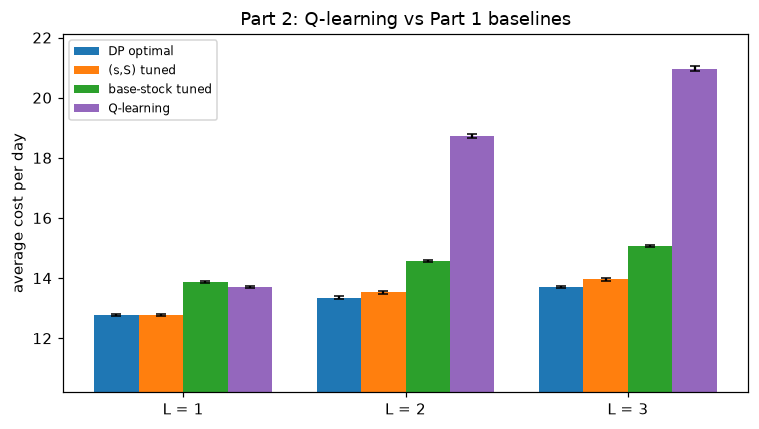

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
plotting.plot_methods_by_L(compare, ax=ax)
ax.set_title("Part 2: Q-learning vs Part 1 baselines")
fig.tight_layout()
plotting.save(fig, PART2 / "final_comparison.png")
plt.show()

## 13. Sensitivity to α and ε

We vary one hyperparameter at a time (the other fixed at the default), with **5 seeds** and the same 200,000-step budget. Reported metric: gap to DP (%) after averaging Q-tables and evaluating greedily on `EVAL_SEEDS`.

In [22]:
SENS_SEEDS = tuple(range(5))
SENS_ALPHAS = (0.05, 0.1, 0.3)
SENS_EPSILONS = (0.05, 0.1, 0.2)
SENS_LS = (1, 2)

sens_rows = []
t_sens = time.perf_counter()
for L in SENS_LS:
    cfg = configs[L]
    dp_pol = TabularPolicy(vi_results[L].policy, cfg)
    dp_eval = evaluate_policy(dp_pol, cfg)

    for alpha in SENS_ALPHAS:
        runs = [
            train_q_learning(cfg, seed=s, total_steps=TRAIN_STEPS, alpha=alpha, epsilon=EPSILON,
                             eval_every=TRAIN_STEPS, checkpoint_days=CHECKPOINT_DAYS,
                             checkpoint_burn_in=CHECKPOINT_BURN_IN, target_cost=dp_costs[L])
            for s in SENS_SEEDS
        ]
        actions = np.mean([r.Q for r in runs], axis=0).argmax(axis=1).astype(np.int64)
        sim = evaluate_policy(TabularPolicy(actions, cfg), cfg)
        gap, gap_ci = paired_gap_pct(sim.avg_cost, dp_eval.avg_cost)
        sens_rows.append(dict(L=L, sweep="alpha", alpha=alpha, epsilon=EPSILON,
                              cost=float(sim.avg_cost.mean()), gap_dp_pct=gap, gap_dp_ci=gap_ci))

    for eps in SENS_EPSILONS:
        runs = [
            train_q_learning(cfg, seed=s, total_steps=TRAIN_STEPS, alpha=ALPHA, epsilon=eps,
                             eval_every=TRAIN_STEPS, checkpoint_days=CHECKPOINT_DAYS,
                             checkpoint_burn_in=CHECKPOINT_BURN_IN, target_cost=dp_costs[L])
            for s in SENS_SEEDS
        ]
        actions = np.mean([r.Q for r in runs], axis=0).argmax(axis=1).astype(np.int64)
        sim = evaluate_policy(TabularPolicy(actions, cfg), cfg)
        gap, gap_ci = paired_gap_pct(sim.avg_cost, dp_eval.avg_cost)
        sens_rows.append(dict(L=L, sweep="epsilon", alpha=ALPHA, epsilon=eps,
                              cost=float(sim.avg_cost.mean()), gap_dp_pct=gap, gap_dp_ci=gap_ci))

sensitivity_ql = pd.DataFrame(sens_rows)
sensitivity_ql.to_csv(PART2 / "sensitivity_alpha_epsilon.csv", index=False)
print(f"sensitivity wall time: {time.perf_counter() - t_sens:.1f}s")
sensitivity_ql

sensitivity wall time: 214.3s


,L,sweep,alpha,epsilon,cost,gap_dp_pct,gap_dp_ci
0,1,alpha,0.05,0.10,14.243,11.575,0.310
1,1,alpha,0.10,0.10,15.360,20.328,0.335
2,1,alpha,0.30,0.10,13.124,2.814,0.217
3,1,epsilon,0.10,0.05,14.845,16.297,0.314
4,1,epsilon,0.10,0.10,15.360,20.328,0.335
5,1,epsilon,0.10,0.20,13.474,5.551,0.238
6,2,alpha,0.05,0.10,17.965,34.580,0.309
7,2,alpha,0.10,0.10,40.005,199.688,0.768
8,2,alpha,0.30,0.10,21.065,57.805,1.173
9,2,epsilon,0.10,0.05,16.925,26.792,0.311


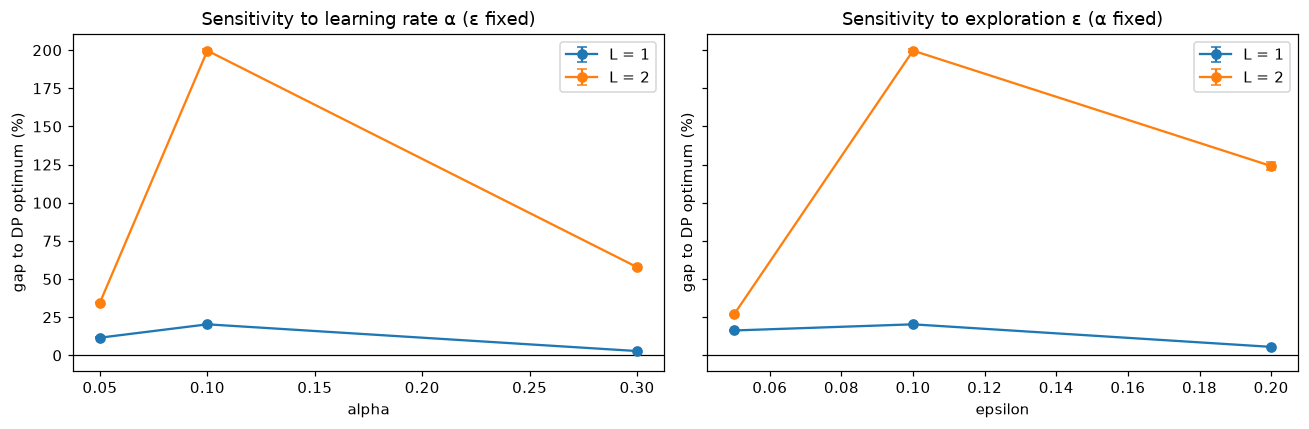

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plotting.plot_hyperparam_sensitivity(
    sensitivity_ql[sensitivity_ql.sweep == "alpha"], x="alpha", ax=axes[0])
axes[0].set_title("Sensitivity to learning rate α (ε fixed)")
plotting.plot_hyperparam_sensitivity(
    sensitivity_ql[sensitivity_ql.sweep == "epsilon"], x="epsilon", ax=axes[1])
axes[1].set_title("Sensitivity to exploration ε (α fixed)")
fig.tight_layout()
plotting.save(fig, PART2 / "sensitivity_alpha_epsilon.png")
plt.show()

## 14. Part 2 findings

In [24]:
for _, row in ql_summary.iterrows():
    L = int(row.L)
    print(
        f"L={L}: Q-learning {row.cost:.2f}/day "
        f"(+{row.gap_dp_pct:.2f}% vs DP, +/-{row.gap_dp_ci:.2f}; "
        f"{row.gap_best_rule_pct:+.2f}% vs tuned (s,S)); "
        f"steps to 5% of DP: {row.steps_to_5pct_dp_mean:.0f} "
        f"({100*row.steps_to_5pct_dp_frac:.0f}% of seeds)"
    )

L=1: Q-learning 13.70/day (+7.30% vs DP, +/-0.25; +7.17% vs tuned (s,S)); steps to 5% of DP: nan (0% of seeds)
L=2: Q-learning 18.74/day (+40.38% vs DP, +/-0.17; +38.57% vs tuned (s,S)); steps to 5% of DP: nan (0% of seeds)
L=3: Q-learning 20.97/day (+53.07% vs DP, +/-0.38; +50.26% vs tuned (s,S)); steps to 5% of DP: nan (0% of seeds)


**Findings (Part 2)** — numbers from esults/part2/\:

1. **Model-free Q-learning runs, but with the default budget (α=0.1, ε=0.1, 200k steps) it does not match DP.** Final greedy gaps are about **+7% (L=1)**, **+40% (L=2)**, and **+53% (L=3)** vs the Part 1 optimum. No seed reached within 5% of DP in 200k steps.
2. **Larger lead times are much harder for tabular Q-learning.** The state–action table grows with L, so the same step budget leaves the agent farther from optimal as delay increases — consistent with the P30 scaling story.
3. **Hyperparameters matter a lot (protocol rule 6).** At L=1, raising α to **0.3** cut the gap to about **+2.8%**, while α=0.05 or poorly matched ε can be much worse. At L=2, some α/ε settings were unstable (very large gaps), so sensitivity is not optional.
4. **Tuned (s,S) from Part 1 remains the stronger practical baseline** for these short delays under this training budget; Q-learning is a valid model-free attempt but needs more steps and careful α/ε to compete.
5. **Compute (protocol rule 5):** training is a few seconds per seed (~3.6–5.0s mean); final eval is ~0.35s. Sample-efficiency-to-5%-of-DP is undefined here because the target was never hit.

**Next (Part 3):** DQN or PPO, delay sweep L = 1…6, and rliable IQM statistics — where approximate methods must replace exact DP.


## 15. Compute cost for Q-learning (protocol rule 5)

This section is **Part 2 only** — Part 1 §7 is left unchanged. We report wall-clock training time (mean over training seeds), final greedy evaluation time, and sample efficiency (steps to within 5% of DP).

In [25]:
compute_ql = ql_summary[["L", "train_seconds_mean", "eval_seconds",
                         "steps_to_5pct_dp_mean", "steps_to_5pct_dp_frac"]].copy()
compute_ql = compute_ql.rename(columns={
    "train_seconds_mean": "train_seconds_mean (10 seeds)",
    "eval_seconds": "final_eval_seconds",
    "steps_to_5pct_dp_mean": "steps_to_5pct_of_DP (mean over seeds that hit)",
    "steps_to_5pct_dp_frac": "fraction_of_seeds_hitting_target",
})
compute_ql.to_csv(PART2 / "compute_time.csv", index=False)
print(hardware["cpu"], "|", hardware["logical cores"], "logical cores |", hardware["os"])
print(f"Python {hardware['python']} | numpy {hardware['numpy']} | gymnasium {hardware['gymnasium']}")
compute_ql

AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD | 16 logical cores | Windows-11-10.0.26200-SP0
Python 3.14.3 | numpy 2.5.4 | gymnasium 1.4.0


,L,train_seconds_mean (10 seeds),final_eval_seconds,steps_to_5pct_of_DP (mean over seeds that hit),fraction_of_seeds_hitting_target
0,1,3.583,0.367,NaN,0.0
1,2,4.568,0.370,NaN,0.0
2,3,4.961,0.353,NaN,0.0


## 16. Part 3 protocol and budget

Part 1 solved the MDP exactly for L = 1, 2, 3 and tuned the industry rules. Part 2 showed that a **tabular** Q-function does not close that gap under a fixed step budget, and that the gap grows with the delay. Part 3 asks the scaling question: replace the table with a small neural network and push the delay to L = 6, where exact DP no longer fits.

**Why DQN, not PPO.** The action is a discrete order quantity, and Part 2 already learned Q(s, a). DQN is that same update with a network instead of one row per state, so L = 1 to 3 compares tabular Q with approximate Q. PPO can act discretely too, but it is on-policy: each transition is used once and then discarded, so it needs more environment steps for the same coverage. That is the wrong tradeoff on a CPU budget. If the DQN curves at large L are too unstable to interpret, PPO is the follow-up, not the default.

The cell below is the only place the training budget is set. Later cells read these names. A heavier run is `DQN_STEPS = 200_000` and `DQN_SEEDS = tuple(range(10))`. Sensitivity uses the same `DQN_STEPS`. Evaluation length, burn-in, and `EVAL_SEEDS` stay the Part 1 constants.

| Protocol piece | Part 3 choice |
|---|---|
| Seeds | `DQN_SEEDS` training seeds (default 5). Each greedy policy is scored on the same 10 `EVAL_SEEDS` as Part 1 |
| Equal budget | `DQN_STEPS` environment steps (default 100,000) for every L and every sensitivity run |
| Learning curves | Greedy checkpoint cost every `EVAL_EVERY` steps (mean ± 95% CI) |
| Final performance | Deterministic greedy network, evaluated with the Part 1 simulator |
| Efficiency | Wall-clock train/eval time, steps to within 5% of DP (L ≤ 3), and steps to within 5% of tuned (s, S) |
| Sensitivity | Learning rate at L = 1 and L = 4 |
| Statistics | rliable IQM of per-seed average cost across lead times |


In [ ]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "IN_COLAB" not in globals():
    raise RuntimeError("Run the setup cells in section 0 first.")
if IN_COLAB:
    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "torch", "stable-baselines3", "rliable==1.2.0",
    ])

try:
    import torch
    import stable_baselines3
    import rliable
except ImportError as exc:
    raise ImportError(
        "Part 3 needs torch, stable-baselines3, arch, and rliable.\n"
        "  pip install -r requirements.txt\n"
        "  pip install --no-deps rliable==1.2.0\n"
        "rliable 1.2 asks for arch<8, which has no Windows wheel on Python 3.14. "
        "requirements.txt installs arch==8.0.0; rliable is then installed with --no-deps."
    ) from exc

for _name in ("ROOT", "hardware", "vi_results", "ss_tuning", "bs_tuning", "summary"):
    if _name not in globals():
        raise RuntimeError(f"Run the Part 1 cells first (missing `{_name}`).")

PART3 = ROOT / "results" / "part3"
PART3.mkdir(parents=True, exist_ok=True)

# --- edit this cell to change the Part 3 budget, then re-run from here ---
DQN_STEPS = 100_000          # set to 200_000 for the heavier run
DQN_SEEDS = tuple(range(5))  # set to tuple(range(10)) for 10 seeds
EVAL_EVERY = 10_000
DQN_LR = 1e-3
DQN_DEVICE = "cpu"           # "auto" or "cuda" when a GPU is available
SENS_LRS = (1e-4, 1e-3, 3e-3)
SENS_SEEDS = DQN_SEEDS[:3]   # or DQN_SEEDS to match the main sweep
SENS_LS = (1, 4)
CHECKPOINT_DAYS = 2_000
CHECKPOINT_BURN_IN = 200
PART3_LS = (1, 2, 3, 4, 5, 6)

print(
    f"Part 3 budget: {DQN_STEPS} steps x {len(DQN_SEEDS)} seeds x L in {PART3_LS}\n"
    f"torch {torch.__version__} | stable-baselines3 {stable_baselines3.__version__} | device {DQN_DEVICE}"
)


## 17. Baselines through L = 6

Exact DP is reused for L = 1, 2, 3 (`vi_results` from Part 1). It is not run for L = 4, 5, 6: the state model is already about 0.85 GB at L = 5 and about 9 GB at L = 6. Base-stock and (s, S) are retuned for any lead time that Part 1 did not tune, on the same tuning seeds, then scored on `EVAL_SEEDS`.


In [ ]:
from inventory_rl.config import DEFAULT
from inventory_rl.evaluate import evaluate_policy, mean_ci, paired_gap_pct
from inventory_rl.policies import BaseStockPolicy, SSPolicy, TabularPolicy
from inventory_rl.tuning import tune_base_stock, tune_ss

part3_configs = {L: DEFAULT.with_(L=L) for L in PART3_LS}
for L in PART3_LS:
    if L not in ss_tuning:
        cfg = part3_configs[L]
        print(f"tuning rules for L={L} (states={cfg.n_states}) ...", flush=True)
        bs_tuning[L] = tune_base_stock(cfg)
        ss_tuning[L] = tune_ss(cfg)
        print(
            f"  base-stock S={bs_tuning[L].best['S']}, "
            f"(s,S)=({ss_tuning[L].best['s']}, {ss_tuning[L].best['S']}), "
            f"{bs_tuning[L].seconds + ss_tuning[L].seconds:.1f}s",
            flush=True,
        )

baseline_eval = {}
for L in PART3_LS:
    cfg = part3_configs[L]
    ss, bs = ss_tuning[L].best, bs_tuning[L].best
    policies = {
        "(s,S) tuned": SSPolicy(ss["s"], ss["S"], cfg),
        "base-stock tuned": BaseStockPolicy(bs["S"], cfg),
    }
    if L in vi_results:
        policies = {"DP optimal": TabularPolicy(vi_results[L].policy, cfg), **policies}
    for name, pol in policies.items():
        baseline_eval[(name, L)] = evaluate_policy(pol, cfg)

baseline_rows = []
for L in PART3_LS:
    ref_dp = baseline_eval.get(("DP optimal", L))
    ref_ss = baseline_eval[("(s,S) tuned", L)]
    names = [n for n in ("DP optimal", "(s,S) tuned", "base-stock tuned") if (n, L) in baseline_eval]
    for name in names:
        sim = baseline_eval[(name, L)]
        cost, cost_ci = mean_ci(sim.avg_cost)
        if ref_dp is None:
            gap_dp, gap_dp_ci = float("nan"), float("nan")
        else:
            gap_dp, gap_dp_ci = paired_gap_pct(sim.avg_cost, ref_dp.avg_cost)
        gap_ss, gap_ss_ci = paired_gap_pct(sim.avg_cost, ref_ss.avg_cost)
        ss, bs = ss_tuning[L].best, bs_tuning[L].best
        params = {"DP optimal": "-", "(s,S) tuned": f"s={ss['s']}, S={ss['S']}",
                  "base-stock tuned": f"S={bs['S']}"}[name]
        baseline_rows.append(dict(
            L=L, method=name, params=params, cost=cost, cost_ci=cost_ci,
            gap_dp_pct=gap_dp, gap_dp_ci=gap_dp_ci, gap_ss_pct=gap_ss, gap_ss_ci=gap_ss_ci,
            ci_over="eval seeds",
        ))

p3_baselines = pd.DataFrame(baseline_rows)
p3_dp_costs = {int(r.L): float(r.cost) for r in p3_baselines.itertuples() if r.method == "DP optimal"}
p3_ss_costs = {int(r.L): float(r.cost) for r in p3_baselines.itertuples() if r.method == "(s,S) tuned"}
p3_baselines.to_csv(PART3 / "baselines_L1_to_L6.csv", index=False)
p3_baselines


## 18. Train DQN

One continuing trajectory per lead time and seed. Every `EVAL_EVERY` steps the greedy network is scored with the same short probe as Part 2 (2,000 days, 200-day burn-in). The network sees observations scaled to [0, 1]; the fast simulator used for the probe and the final eval does not.


In [ ]:
from inventory_rl.agents.dqn import first_within, train_dqn

dqn_runs = {L: [] for L in PART3_LS}
t_train = time.perf_counter()
for L in PART3_LS:
    cfg = part3_configs[L]
    for seed in DQN_SEEDS:
        result = train_dqn(
            cfg,
            seed=seed,
            total_steps=DQN_STEPS,
            learning_rate=DQN_LR,
            eval_every=EVAL_EVERY,
            checkpoint_days=CHECKPOINT_DAYS,
            checkpoint_burn_in=CHECKPOINT_BURN_IN,
            device=DQN_DEVICE,
        )
        dqn_runs[L].append(result)
        print(
            f"L={L} seed={seed}: train {result.seconds:.1f}s, "
            f"final checkpoint cost {result.eval_costs[-1]:.2f}",
            flush=True,
        )
print(f"total DQN training wall time: {time.perf_counter() - t_train:.1f}s")

steps0 = dqn_runs[PART3_LS[0]][0].checkpoints
np.savez(
    PART3 / "learning_curves.npz",
    steps=steps0,
    **{f"L{L}": np.stack([r.eval_costs for r in dqn_runs[L]]) for L in PART3_LS},
    **{f"steps_to_ss_L{L}": np.array([
        first_within(r.eval_costs, r.checkpoints, p3_ss_costs[L]) for r in dqn_runs[L]
    ]) for L in PART3_LS},
    **{f"steps_to_dp_L{L}": np.array([
        first_within(r.eval_costs, r.checkpoints, p3_dp_costs.get(L)) for r in dqn_runs[L]
    ]) for L in PART3_LS},
    **{f"train_seconds_L{L}": np.array([r.seconds for r in dqn_runs[L]]) for L in PART3_LS},
)


## 19. Learning curves

Mean greedy checkpoint cost across training seeds, with a 95% confidence band. Dotted lines are DP (only L = 1, 2, 3). Dashed lines are tuned (s, S).


In [ ]:
import inventory_rl.plotting as plotting

curves = {
    L: (dqn_runs[L][0].checkpoints, np.stack([r.eval_costs for r in dqn_runs[L]]))
    for L in PART3_LS
}
fig, ax = plt.subplots(figsize=(8, 4.5))
plotting.plot_learning_curves(curves, p3_dp_costs, p3_ss_costs, ax=ax, method="DQN")
fig.tight_layout()
plotting.save(fig, PART3 / "learning_curves.png")
plt.show()


## 20. Final evaluation

Each training seed keeps its own network. Averaging Q-tables, as in the Part 2 sensitivity, is not done here: the seeds are aggregated only after each greedy policy has been scored. The cost for a seed is the mean over `EVAL_SEEDS`. The confidence interval is across **training** seeds. Baseline intervals above are across evaluation seeds; the `ci_over` column records which one.

Gap versus DP is defined only for L = 1, 2, 3. Gap versus tuned (s, S) is defined for every L.


In [ ]:
def _finite_mean(values):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    return float(finite.mean()) if finite.size else float("nan")

dqn_rows = []
dqn_seed_cost = {}
t_eval = {}
for L in PART3_LS:
    cfg = part3_configs[L]
    ref_ss = baseline_eval[("(s,S) tuned", L)]
    ref_dp = baseline_eval.get(("DP optimal", L))
    seed_costs, seed_gap_ss, seed_gap_dp = [], [], []
    t0 = time.perf_counter()
    for result in dqn_runs[L]:
        sim = evaluate_policy(result.policy, cfg)
        seed_costs.append(float(sim.avg_cost.mean()))
        seed_gap_ss.append(paired_gap_pct(sim.avg_cost, ref_ss.avg_cost)[0])
        if ref_dp is not None:
            seed_gap_dp.append(paired_gap_pct(sim.avg_cost, ref_dp.avg_cost)[0])
    t_eval[L] = time.perf_counter() - t0
    dqn_seed_cost[L] = np.asarray(seed_costs, dtype=float)
    cost, cost_ci = mean_ci(seed_costs)
    gap_ss, gap_ss_ci = mean_ci(seed_gap_ss)
    gap_dp, gap_dp_ci = (mean_ci(seed_gap_dp) if seed_gap_dp else (float("nan"), float("nan")))
    steps_dp = np.array([
        first_within(r.eval_costs, r.checkpoints, p3_dp_costs.get(L)) for r in dqn_runs[L]
    ], dtype=float)
    steps_ss = np.array([
        first_within(r.eval_costs, r.checkpoints, p3_ss_costs[L]) for r in dqn_runs[L]
    ], dtype=float)
    dqn_rows.append(dict(
        L=L, method="DQN",
        params=f"lr={DQN_LR}, steps={DQN_STEPS}, seeds={len(DQN_SEEDS)}",
        cost=cost, cost_ci=cost_ci,
        gap_dp_pct=gap_dp, gap_dp_ci=gap_dp_ci,
        gap_ss_pct=gap_ss, gap_ss_ci=gap_ss_ci,
        ci_over="train seeds",
        steps_to_5pct_dp_mean=_finite_mean(steps_dp),
        steps_to_5pct_dp_frac=float(np.isfinite(steps_dp).mean()),
        steps_to_5pct_ss_mean=_finite_mean(steps_ss),
        steps_to_5pct_ss_frac=float(np.isfinite(steps_ss).mean()),
        train_seconds_mean=float(np.mean([r.seconds for r in dqn_runs[L]])),
        eval_seconds=t_eval[L],
    ))

dqn_summary = pd.DataFrame(dqn_rows)
dqn_summary.to_csv(PART3 / "final_evaluation_dqn.csv", index=False)

compare_rows = [p3_baselines]
if "ql_summary" in globals():
    ql_rows = ql_summary.copy()
    ql_rows["gap_ss_pct"] = ql_rows["gap_best_rule_pct"]
    ql_rows["gap_ss_ci"] = ql_rows.get("gap_best_rule_ci", np.nan)
    ql_rows["ci_over"] = "eval seeds"
    compare_rows.append(ql_rows[["L", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci",
                                 "gap_ss_pct", "gap_ss_ci", "ci_over"]])
compare_rows.append(dqn_summary[["L", "method", "params", "cost", "cost_ci", "gap_dp_pct", "gap_dp_ci",
                                 "gap_ss_pct", "gap_ss_ci", "ci_over"]])
p3_compare = pd.concat(compare_rows, ignore_index=True)
p3_compare.to_csv(PART3 / "comparison_with_baselines.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for method, rows in p3_compare.groupby("method", sort=False):
    rows = rows.sort_values("L")
    ax.errorbar(rows.L, rows.gap_ss_pct, yerr=rows.gap_ss_ci, marker="o", capsize=3, label=method)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(list(PART3_LS))
ax.set_xlabel("lead time L")
ax.set_ylabel("gap to tuned (s, S) (%)")
ax.set_title("Final gap versus tuned (s, S)")
ax.legend(fontsize=8)
fig.tight_layout()
plotting.save(fig, PART3 / "gap_vs_lead_time.png")
plt.show()
p3_compare


## 21. rliable IQM

The score matrix has one row per **training** seed and one column per lead time. The entry is that seed's mean evaluation cost. Costs are negated before the IQM so that higher is better, which is the convention in rliable. The printed cost IQM is that value with the sign put back. The interval is a 95% stratified bootstrap confidence interval.


In [ ]:
from inventory_rl.rliable_compat import iqm_cost_interval

dqn_matrix = np.column_stack([dqn_seed_cost[L] for L in PART3_LS])  # (seeds, lead times)

def _iqm_cost(matrix):
    # rliable IQM on negated cost, returned on the cost scale. The helper also
    # covers arch 8, which renamed the bootstrap `random_state` argument.
    return iqm_cost_interval(matrix, reps=5_000, seed=0)

iqm_rows = []
for i, L in enumerate(PART3_LS):
    iqm, lo, hi = _iqm_cost(dqn_matrix[:, i:i + 1])
    iqm_rows.append(dict(L=L, iqm_cost=iqm, ci_low=lo, ci_high=hi))
iqm_by_L = pd.DataFrame(iqm_rows)
agg_iqm, agg_lo, agg_hi = _iqm_cost(dqn_matrix)
iqm_by_L.to_csv(PART3 / "iqm_by_L.csv", index=False)
pd.DataFrame([dict(scope="L=1..6", iqm_cost=agg_iqm, ci_low=agg_lo, ci_high=agg_hi,
                   seeds=len(DQN_SEEDS), steps=DQN_STEPS)]).to_csv(
    PART3 / "iqm_aggregate.csv", index=False
)
print(
    f"IQM cost across L=1..6: {agg_iqm:.3f} "
    f"(95% bootstrap CI {agg_lo:.3f} to {agg_hi:.3f})"
)
iqm_by_L


## 22. Learning-rate sensitivity, compute, and findings

One factor at a time: learning rate in `SENS_LRS`, lead times in `SENS_LS`, seeds `SENS_SEEDS`, and the same `DQN_STEPS` as the main sweep. The reported gap is versus tuned (s, S), so L = 4 (no DP) sits on the same axis as L = 1. The main comparison above stays at `DQN_LR`.


In [ ]:
sens_rows = []
t_sens = time.perf_counter()
for L in SENS_LS:
    cfg = part3_configs[L]
    ref_ss = baseline_eval[("(s,S) tuned", L)].avg_cost
    for lr in SENS_LRS:
        gaps, costs = [], []
        for seed in SENS_SEEDS:
            result = train_dqn(
                cfg, seed=seed, total_steps=DQN_STEPS, learning_rate=lr,
                eval_every=DQN_STEPS, checkpoint_days=CHECKPOINT_DAYS,
                checkpoint_burn_in=CHECKPOINT_BURN_IN, device=DQN_DEVICE,
            )
            sim = evaluate_policy(result.policy, cfg)
            costs.append(float(sim.avg_cost.mean()))
            gaps.append(paired_gap_pct(sim.avg_cost, ref_ss)[0])
            print(f"sensitivity L={L} lr={lr} seed={seed}: cost {costs[-1]:.2f}", flush=True)
        cost, cost_ci = mean_ci(costs)
        gap, gap_ci = mean_ci(gaps)
        sens_rows.append(dict(
            L=L, learning_rate=lr, seeds=len(SENS_SEEDS), steps=DQN_STEPS,
            cost=cost, cost_ci=cost_ci, gap_ss_pct=gap, gap_ss_ci=gap_ci,
        ))
sensitivity_dqn = pd.DataFrame(sens_rows)
sensitivity_dqn.to_csv(PART3 / "sensitivity_learning_rate.csv", index=False)
print(f"sensitivity wall time: {time.perf_counter() - t_sens:.1f}s")

fig, ax = plt.subplots(figsize=(6, 4))
for L, rows in sensitivity_dqn.groupby("L"):
    rows = rows.sort_values("learning_rate")
    ax.errorbar(rows.learning_rate, rows.gap_ss_pct, yerr=rows.gap_ss_ci,
                marker="o", capsize=3, label=f"L = {L}")
ax.set_xscale("log")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("learning rate")
ax.set_ylabel("gap to tuned (s, S) (%)")
ax.set_title("DQN learning-rate sensitivity")
ax.legend()
fig.tight_layout()
plotting.save(fig, PART3 / "sensitivity_learning_rate.png")
plt.show()
sensitivity_dqn


### Compute and how to read the result

`steps_to_5pct_*` is the mean, over seeds that hit, of the first checkpoint within 5% of that reference. A NaN with fraction 0 means no seed hit. That is a result, not a missing value. Gap versus DP is blank for L = 4, 5, 6 because there is no exact optimum. The question for those lead times is the gap versus tuned (s, S), not a claim that DQN beats DP.


In [ ]:
compute_dqn = dqn_summary[[
    "L", "train_seconds_mean", "eval_seconds",
    "steps_to_5pct_dp_mean", "steps_to_5pct_dp_frac",
    "steps_to_5pct_ss_mean", "steps_to_5pct_ss_frac",
]].copy()
compute_dqn.to_csv(PART3 / "compute_time.csv", index=False)
print(hardware["cpu"], "|", hardware["logical cores"], "logical cores |", hardware["os"])
print(
    f"Python {hardware['python']} | torch {torch.__version__} | "
    f"stable-baselines3 {stable_baselines3.__version__}"
)
print(
    f"Budget that produced these tables: {len(DQN_SEEDS)} seeds x {DQN_STEPS} steps, "
    f"lr={DQN_LR}, device={DQN_DEVICE}."
)
for row in dqn_summary.itertuples():
    dp_txt = "n/a (no DP)" if not np.isfinite(row.gap_dp_pct) else f"{row.gap_dp_pct:+.2f}% vs DP"
    hit_dp = "n/a" if not np.isfinite(row.steps_to_5pct_dp_frac) else (
        f"{row.steps_to_5pct_dp_mean:.0f} ({100 * row.steps_to_5pct_dp_frac:.0f}% of seeds)"
        if row.steps_to_5pct_dp_frac > 0 else "never (0% of seeds)"
    )
    hit_ss = (
        f"{row.steps_to_5pct_ss_mean:.0f} ({100 * row.steps_to_5pct_ss_frac:.0f}% of seeds)"
        if row.steps_to_5pct_ss_frac > 0 else "never (0% of seeds)"
    )
    print(
        f"L={int(row.L)}: DQN {row.cost:.2f}/day ({dp_txt}; {row.gap_ss_pct:+.2f}% vs tuned (s,S)); "
        f"steps to 5% of DP: {hit_dp}; steps to 5% of (s,S): {hit_ss}"
    )
print(
    "Read the (s, S) gap at every L. A positive gap means DQN is more expensive than the tuned rule. "
    "Whether that gap shrinks or grows from L=1 to L=6 is the Part 3 result."
)
compute_dqn
